<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/neural-networks/Lab1_Perceptron_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório 1 — O Perceptron *from scratch*

**Fundamentos de Redes Neurais Artificiais** · Aula 1

Roteiro:

1. **Os dados** e **o neurônio**: a previsão vetorizada.
2. **O laço de aprendizagem**: as três linhas que contêm a regra do Perceptron.
3. **A fronteira de decisão**: a reta final e a reta girando época a época.
4. **O exemplo**: o mesmo algoritmo, passo a passo, nos quatro pontos dos slides.
5. **Quatro experimentos**: cada um começa com uma pergunta.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (5.2, 4.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
AZUL, VERMELHO, TINTA = "#7C90B0", "#DB1E2F", "#231F20"
print("pronto")

pronto


## 1. Os dados

Duas nuvens gaussianas em R². A classe é o que queremos prever: 0 ou 1.

X: (100, 2)  y: (100,)  classes: [0 1]


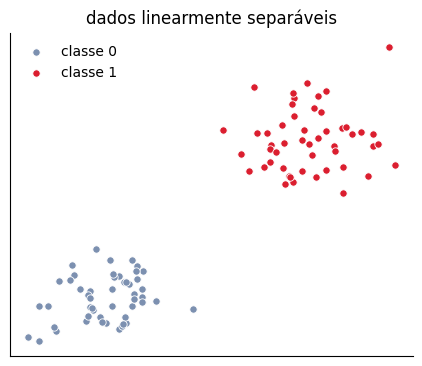

In [ ]:
def gera_dados(n=50, sep=2.0, ruido=0.8, seed=42):
    rng = np.random.default_rng(seed)
    A = rng.normal([-sep, -sep], ruido, (n, 2))
    B = rng.normal([ sep,  sep], ruido, (n, 2))
    X = np.vstack([A, B])
    y = np.hstack([np.zeros(n), np.ones(n)]).astype(int)
    return X, y


def desenha(X, y, titulo=""):
    plt.scatter(*X[y == 0].T, s=28, color=AZUL, edgecolor="white", lw=.6, label="classe 0")
    plt.scatter(*X[y == 1].T, s=28, color=VERMELHO, edgecolor="white", lw=.6, label="classe 1")
    plt.legend(frameon=False); plt.title(titulo); plt.xticks([]); plt.yticks([])


X, y = gera_dados()
print("X:", X.shape, " y:", y.shape, " classes:", np.unique(y))
desenha(X, y, "dados linearmente separáveis"); plt.show()

## 2. O neurônio

$$ z = w^\top x + b \qquad\qquad \hat{y} = \text{step}(z) $$

Repare que `predizer` **não tem laço**. `X @ w` calcula as `m` previsões de uma vez —
é a vetorização de que falamos no começo da aula.

In [ ]:
def step(z):
    return np.where(z >= 0, 1, 0)


def predizer(X, w, b):
    # X tem shape (m, n)  ·  w tem shape (n,)  ·  resultado (m,)
    return step(X @ w + b)


# teste rápido de shapes
w_teste = np.array([1.0, 1.0])
print("shape da previsão:", predizer(X, w_teste, 0.0).shape, " esperado:", (X.shape[0],))

shape da previsão: (100,)  esperado: (100,)


## 3. O laço de aprendizagem

Toda a regra do Perceptron está em três linhas da função abaixo. Vale olhar cada uma antes de rodar:

1. **`delta = yi - y_hat`** — o erro é *rótulo − previsão*. Ele vale **+1** quando a rede disse 0 e
   deveria dizer 1, **−1** no caso contrário, e **0** quando acertou.

2. **`w = w + eta * delta * xi`** — com `delta = +1`, somamos `x` a `w`: o vetor de pesos gira
   **na direção** do exemplo, e o exemplo passa para o lado positivo da fronteira. Com `delta = −1`,
   subtraímos `x`: o vetor gira **para longe** dele. O bias faz o mesmo, deslocando a reta.

3. **`if delta != 0`** — repare que, se a atualização fosse feita sempre, **os pesos seriam os mesmos**:
   com `delta = 0`, o termo `eta * delta * xi` é zero. O `if` existe para **contar os erros** da época,
   que é o que o laço usa para decidir quando parar.

A função também aceita `w0` e `b0` para escolhermos o ponto de partida. Vamos usar isso na seção 4.

In [ ]:
def treina_perceptron(X, y, eta=0.1, epocas=30, seed=0, init="aleatorio", escala=0.01,
                      w0=None, b0=0.0):
    rng = np.random.default_rng(seed)
    if w0 is not None:                       # ponto de partida escolhido por nós
        w = np.array(w0, dtype=float)
    elif init == "zeros":
        w = np.zeros(X.shape[1])
    else:
        w = rng.normal(0, escala, X.shape[1])
    b = float(b0)
    historico = []

    for ep in range(epocas):
        erros = 0
        for xi, yi in zip(X, y):
            y_hat = step(np.dot(xi, w) + b)    # previsão para este exemplo

            delta = yi - y_hat                 # erro: +1, -1 ou 0

            if delta != 0:                     # errou: corrige e conta
                w = w + eta * delta * xi       # gira o vetor de pesos
                b = b + eta * delta            # desloca a fronteira
                erros += 1

        # Guardamos uma CÓPIA de w. Aqui "w = w + ..." já cria um array novo, mas se a
        # atualização fosse escrita como "w += ...", sem a cópia todas as entradas do
        # histórico apontariam para o mesmo array e mostrariam só os pesos finais.
        historico.append((w.copy(), b, erros))
        if erros == 0:                         # uma época inteira sem erros: convergiu
            break
    return w, b, historico

In [ ]:
w, b, hist = treina_perceptron(X, y)
print("w =", np.round(w, 4), " b =", round(b, 4))
print("erros por época:", [h[2] for h in hist])
print("épocas usadas:", len(hist))

w = [0.1769 0.2819]  b = -0.1
erros por época: [1, 0]
épocas usadas: 2


**Leitura do resultado.** `erros por época` conta as **correções feitas durante** cada passada pelos dados.
Nestes dados, o Perceptron erra **um único exemplo** na primeira época; essa correção já basta para separar
as duas nuvens, e a segunda época passa sem erros. Por isso o laço para em duas épocas.

## 4. A fronteira de decisão

A fronteira é o conjunto onde $z = 0$: a reta $w_1 x_1 + w_2 x_2 + b = 0$.

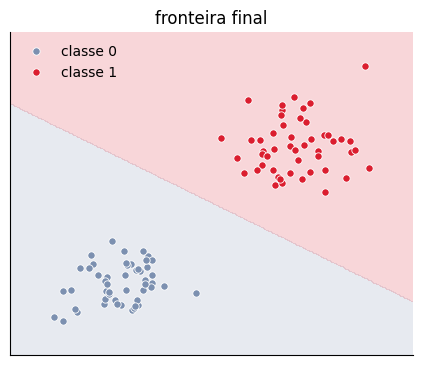

In [ ]:
def plot_fronteira(X, y, w, b, titulo=""):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = predizer(np.c_[xx.ravel(), yy.ravel()], w, b).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=.18, levels=[-.5, .5, 1.5],
                 colors=[AZUL, VERMELHO])
    desenha(X, y, titulo)


plot_fronteira(X, y, w, b, "fronteira final"); plt.show()

### A fronteira girando, época a época

Nos dados acima, a reta só se move **uma vez**: as nuvens estão tão afastadas que uma única correção já
resolve. Se desenhássemos a fronteira ao fim de cada época, todos os gráficos sairiam iguais.

Para ver o algoritmo trabalhar, usamos aqui nuvens **mais próximas**, em ordem embaralhada, e
**de propósito** começamos com uma reta ruim, `w0 = (0.2, −0.6)`, que classifica errado quase todos os pontos.

Em cada gráfico:

- a **linha contínua** é a fronteira ao fim da época;
- a **linha tracejada** é a fronteira da época anterior;
- os pontos **circulados** são os que a reta atual ainda classifica errado.

Atenção a dois números diferentes: o **título** diz quantos pontos a reta erra *ao fim* da época;
o **rodapé** diz quantas correções foram feitas *durante* a época.

correções por época: [8, 2, 1, 0]


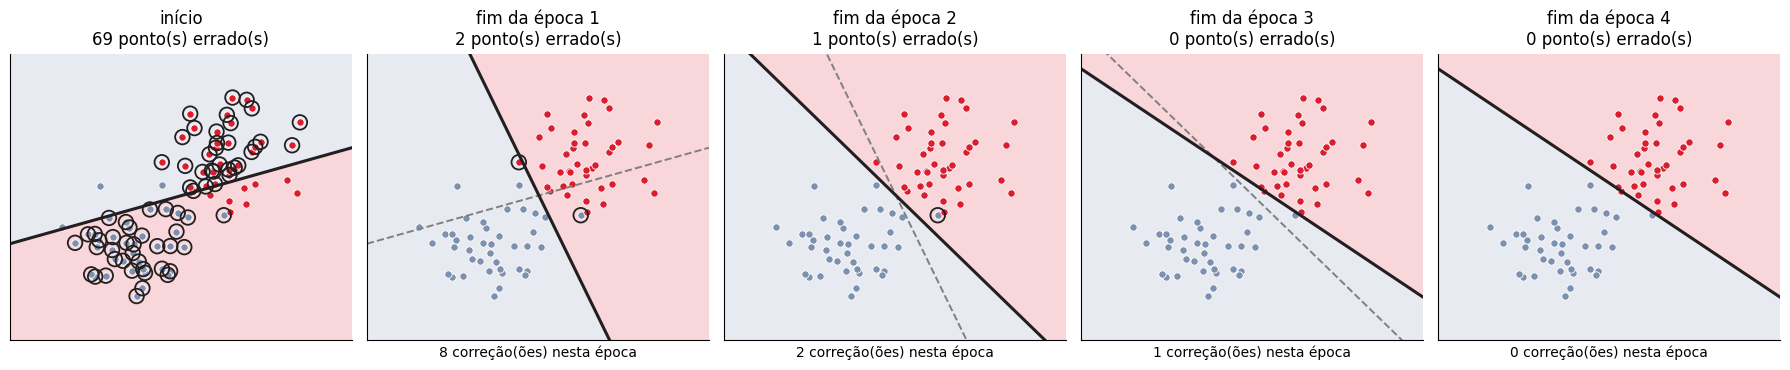

In [ ]:
Xv, yv = gera_dados(n=40, sep=0.9, ruido=0.7, seed=5)
ordem = np.random.default_rng(2).permutation(len(yv))
Xv, yv = Xv[ordem], yv[ordem]

w_ini, b_ini = np.array([0.2, -0.6]), 0.0
_, _, hv = treina_perceptron(Xv, yv, eta=0.1, w0=w_ini, b0=b_ini)
print("correções por época:", [h[2] for h in hv])

# o estado inicial + o estado ao fim de cada época
estados = [(w_ini, b_ini, None)] + hv


def desenha_reta(ax, w, b, X, **kw):
    xs = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 2)
    if abs(w[1]) > 1e-12:
        ax.plot(xs, -(w[0] * xs + b) / w[1], **kw)


fig, axs = plt.subplots(1, len(estados), figsize=(3.6 * len(estados), 3.8))
for k, (ax, (wi, bi, correcoes)) in enumerate(zip(axs, estados)):
    plt.sca(ax)
    errados = predizer(Xv, wi, bi) != yv
    titulo = "início" if k == 0 else f"fim da época {k}"
    plot_fronteira(Xv, yv, wi, bi, f"{titulo}\n{errados.sum()} ponto(s) errado(s)")
    ax.get_legend().remove()
    if k > 0:
        w_ant, b_ant, _ = estados[k - 1]
        desenha_reta(ax, w_ant, b_ant, Xv, color="gray", ls="--", lw=1.4)
        ax.set_xlabel(f"{correcoes} correção(ões) nesta época")
    desenha_reta(ax, wi, bi, Xv, color=TINTA, lw=2.2)
    ax.scatter(*Xv[errados].T, s=110, facecolor="none", edgecolor=TINTA, lw=1.3)
    ax.set_xlim(Xv[:, 0].min() - 1, Xv[:, 0].max() + 1)
    ax.set_ylim(Xv[:, 1].min() - 1, Xv[:, 1].max() + 1)
plt.tight_layout(); plt.show()

**O que observar.** A primeira época faz a maior parte do trabalho: a reta dá um giro grande e sai de quase
todos os pontos errados para apenas dois. Nas épocas seguintes, as correções são poucas e a reta só se ajusta.

Na **última** época a reta não se move: nenhum exemplo foi classificado errado, então nenhuma correção foi
feita. É exatamente essa época sem erros que o laço usa para decidir parar.

## 5. Conferindo o exemplo que fizemos

Nos slides executamos o algoritmo no papel: quatro pontos, $\eta = 1$, $w = (0,0)$, $b = 0$.

Rode a célula e confira se os números batem: **quatro correções**, convergência ao fim da
segunda passada, e $w$ final igual a $(3, 1)$ com $b = 0$.

Se bater, seu `treina_perceptron` está correto.

In [ ]:
X_mao = np.array([[0., 0.], [1., 2.], [-2., 2.], [0., -1.]])
y_mao = np.array([1, 1, 0, 0])


def treina_verboso(X, y, eta=1.0, epocas=4):
    w = np.zeros(X.shape[1]); b = 0.0; correcoes = 0
    for ep in range(epocas):
        erros = 0
        print(f"--- epoca {ep} " + "-" * 44)
        for i, (xi, yi) in enumerate(zip(X, y), start=1):
            z = np.dot(xi, w) + b
            y_hat = step(z)
            e = yi - y_hat
            linha = f"  x{i}={xi}  z={z:+.0f}  y={y_hat}  d={yi}  e={e:+d}"
            if e != 0:
                w = w + eta * e * xi; b = b + eta * e
                erros += 1; correcoes += 1
                linha += f"   ->  w={w}  b={b:+.0f}"
            else:
                linha += "   ->  sem mudanca"
            print(linha)
        if erros == 0:
            print(f"  nenhum erro: o laco para aqui"); break
    print(f"\nw final = {w}   b final = {b:+.0f}   correcoes = {correcoes}")
    return w, b


w_mao, b_mao = treina_verboso(X_mao, y_mao)

--- epoca 0 --------------------------------------------
  x1=[0. 0.]  z=+0  y=1  d=1  e=+0   ->  sem mudanca
  x2=[1. 2.]  z=+0  y=1  d=1  e=+0   ->  sem mudanca
  x3=[-2.  2.]  z=+0  y=1  d=0  e=-1   ->  w=[ 2. -2.]  b=-1
  x4=[ 0. -1.]  z=+1  y=1  d=0  e=-1   ->  w=[ 2. -1.]  b=-2
--- epoca 1 --------------------------------------------
  x1=[0. 0.]  z=-2  y=0  d=1  e=+1   ->  w=[ 2. -1.]  b=-1
  x2=[1. 2.]  z=-1  y=0  d=1  e=+1   ->  w=[3. 1.]  b=+0
  x3=[-2.  2.]  z=-4  y=0  d=0  e=+0   ->  sem mudanca
  x4=[ 0. -1.]  z=-1  y=0  d=0  e=+0   ->  sem mudanca
--- epoca 2 --------------------------------------------
  x1=[0. 0.]  z=+0  y=1  d=1  e=+0   ->  sem mudanca
  x2=[1. 2.]  z=+5  y=1  d=1  e=+0   ->  sem mudanca
  x3=[-2.  2.]  z=-4  y=0  d=0  e=+0   ->  sem mudanca
  x4=[ 0. -1.]  z=-1  y=0  d=0  e=+0   ->  sem mudanca
  nenhum erro: o laco para aqui

w final = [3. 1.]   b final = +0   correcoes = 4


---

# Experimentos

As quatro células seguintes são o coração da aula.

## Experimento 1 — a taxa de aprendizagem

Vamos variar $\eta$ em quatro ordens de grandeza: de 0,001 a 10.
Os pesos começam **em zero**.

> **Preveja:** quantas épocas cada valor de $\eta$ vai levar para convergir?
> Mais alto converge mais rápido? Mais baixo converge mais devagar?

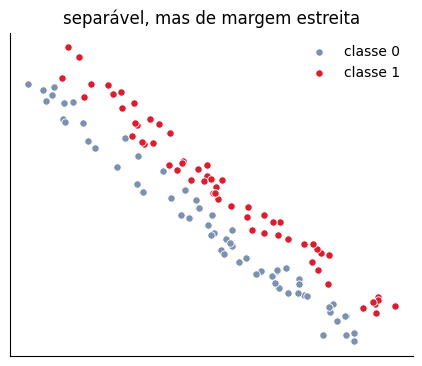

     eta   épocas  erros por época
   0.001        3  [18, 5, 0]
    0.01        3  [18, 5, 0]
     0.1        3  [18, 5, 0]
     1.0        3  [18, 5, 0]
    10.0        3  [18, 5, 0]


In [ ]:
def dados_dificeis(n=60, margem=0.08, espalhamento=6.0, seed=5):
    # duas faixas separáveis, mas com margem estreita e muito espalhamento lateral
    r = np.random.default_rng(seed)
    u = np.array([1., 1.]) / np.sqrt(2)     # direção que separa
    v = np.array([-1., 1.]) / np.sqrt(2)    # direção ortogonal
    tA = r.uniform(margem, margem + 0.9, n)
    tB = r.uniform(-margem - 0.9, -margem, n)
    sA = r.uniform(-espalhamento, espalhamento, n)
    sB = r.uniform(-espalhamento, espalhamento, n)
    X = np.vstack([tB[:, None] * u + sB[:, None] * v,
                   tA[:, None] * u + sA[:, None] * v])
    y = np.hstack([np.zeros(n), np.ones(n)]).astype(int)
    return X, y


Xd, yd = dados_dificeis()
desenha(Xd, yd, "separável, mas de margem estreita"); plt.show()

print(f"{'eta':>8}  {'épocas':>7}  erros por época")
for eta in [0.001, 0.01, 0.1, 1.0, 10.0]:
    _, _, h = treina_perceptron(Xd, yd, eta=eta, init="zeros", epocas=60)
    print(f"{eta:>8}  {len(h):>7}  {[e[2] for e in h]}")

### O que aconteceu

A sequência de erros é **idêntica** para todos os valores de $\eta$.

Não é coincidência, e vale a demonstração. Com $w$ começando em zero, todo peso
é uma soma de termos $\eta\,e\,x$ — ou seja, $w = \eta \cdot (\text{algo})$ e
$b = \eta \cdot (\text{algo})$. Como $\eta > 0$, multiplicar tudo por $\eta$
**não muda o sinal** de $w^\top x + b$. E a decisão do Perceptron depende só do sinal.

> **No Perceptron com inicialização em zero, $\eta$ é irrelevante.** Ele apenas escala os pesos.
>
> Isso vai deixar de valer no Encontro 4, quando a ativação for diferenciável e o algoritmo
> passar a ser gradiente descendente. Lá, $\eta$ decide entre convergir e divergir.

## Experimento 2 — a escala da inicialização

Agora $\eta$ fica fixo em 0,1 e variamos a escala dos pesos iniciais.

> **Preveja:** começar com pesos grandes ajuda, atrapalha, ou é indiferente?

In [ ]:
print(f"{'escala inicial':>15}  {'épocas':>7}  erros por época")
for esc in [0.01, 1.0, 20.0]:
    _, _, h = treina_perceptron(Xd, yd, eta=0.1, init="aleatorio", escala=esc, epocas=60)
    print(f"{esc:>15}  {len(h):>7}  {[e[2] for e in h]}")

_, _, h0 = treina_perceptron(Xd, yd, eta=0.1, init="zeros", epocas=60)
print(f"{'zeros':>15}  {len(h0):>7}  {[e[2] for e in h0]}")

 escala inicial   épocas  erros por época
           0.01        3  [18, 5, 0]
            1.0        5  [8, 12, 8, 12, 0]
           20.0        5  [21, 9, 13, 2, 0]
          zeros        3  [18, 5, 0]


### O que aconteceu

A escala inicial **importa**, e por um motivo diferente do $\eta$: ela muda a
*posição de partida* na superfície, não o tamanho do passo. Pesos iniciais grandes
colocam a fronteira longe do lugar certo, e cada correção de tamanho $\eta$ leva
proporcionalmente menos longe.

Note também que **`zeros` funciona perfeitamente aqui**. Guarde isso: no Encontro 2,
quando tivermos uma camada oculta, inicializar com zeros vai quebrar a rede por completo.
A razão é a simetria entre neurônios — e com um neurônio só não há simetria para quebrar.

## Experimento 3 — e se os dados **não** forem separáveis?

O teorema da convergência exige separabilidade linear. Vamos violar a hipótese:
duas nuvens que se sobrepõem.

> **Preveja:** o algoritmo vai (a) convergir mais devagar, (b) parar numa solução
> aproximada razoável, ou (c) nunca parar?

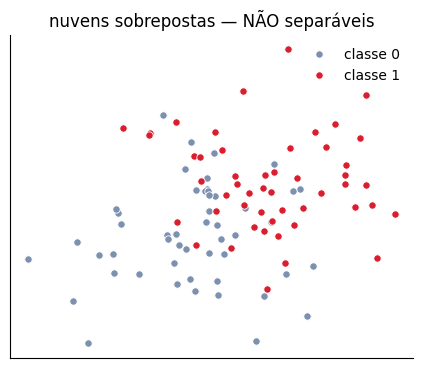

erros por época: [5, 9, 14, 16, 14, 15, 14, 8, 9, 13, 11, 13, 11, 9, 9, 13, 13, 15, 8, 9, 14, 14, 16, 13, 12, 11, 15, 8, 9, 13]
convergiu? NAO — oscila indefinidamente


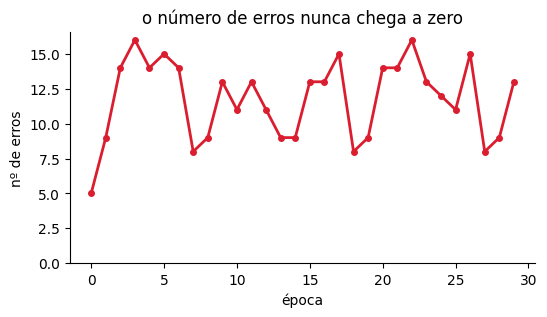

In [ ]:
Xn, yn = gera_dados(n=50, sep=0.6, ruido=1.3, seed=7)
desenha(Xn, yn, "nuvens sobrepostas — NÃO separáveis"); plt.show()

_, _, hn = treina_perceptron(Xn, yn, epocas=30)
erros = [e[2] for e in hn]
print("erros por época:", erros)
print("convergiu?", "sim" if erros[-1] == 0 else "NAO — oscila indefinidamente")

plt.figure(figsize=(6, 3))
plt.plot(erros, "-o", color=VERMELHO, lw=2, ms=4)
plt.xlabel("época"); plt.ylabel("nº de erros"); plt.ylim(bottom=0)
plt.title("o número de erros nunca chega a zero"); plt.show()

### O que aconteceu

O número de erros **oscila para sempre**. Não decresce, não estabiliza, não converge.

E repare numa consequência prática desagradável: se você parar o treino numa época
arbitrária, pega o `w` daquele instante — que pode ser bem pior que o de outras épocas.
O algoritmo não guarda o melhor que já viu.

Esse é o problema que o *Pocket Algorithm* (Gallant, 1990) resolve, guardando a melhor
solução encontrada até o momento.

## Experimento 4 — o XOR

Quatro pontos. (0,0) → 0, (0,1) → 1, (1,0) → 1, (1,1) → 0.

> **Preveja:** antes de rodar, tente desenhar no papel uma reta que separe as classes.

épocas rodadas: 100
erros nas 10 últimas épocas: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


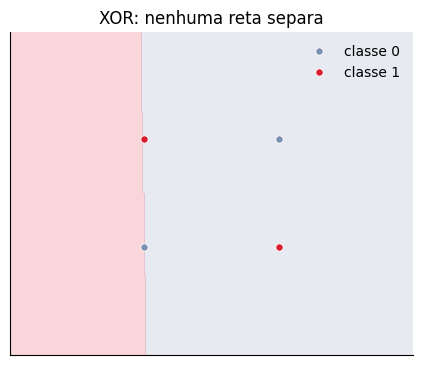

In [ ]:
X_xor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_xor = np.array([0, 1, 1, 0])

w_x, b_x, hx = treina_perceptron(X_xor, y_xor, epocas=100)
print("épocas rodadas:", len(hx))
print("erros nas 10 últimas épocas:", [e[2] for e in hx[-10:]])

plot_fronteira(X_xor, y_xor, w_x, b_x, "XOR: nenhuma reta separa"); plt.show()

### O que aconteceu

Cem épocas, e o número de erros nunca chega a zero.

Isso **não é um defeito do algoritmo**, nem falha do teorema: a hipótese do teorema
era separabilidade linear, e ela não vale aqui. Minsky e Papert provaram, em 1969,
que nenhum Perceptron de uma camada resolve o XOR.

O que falta é **composição**: duas retas resolveriam o problema, mas para ter duas retas
é preciso mais de um neurônio, e uma segunda camada que combine o resultado delas.

É exatamente isso que faremos no Encontro 2.

---

### Para pensar até a próxima aula

1. Quantos neurônios, no mínimo, resolvem o XOR?
2. No Experimento 2, `zeros` funcionou. Por que isso deixará de funcionar num MLP?
3. A regra do Perceptron não minimiza nenhuma função de perda diferenciável.
   Que consequência isso tem para o algoritmo de otimização do Encontro 4?